# Precision-Recall and Imbalance

This notebook studies the precision-recall curve and average precision on a strongly imbalanced dataset, contrasts ROC with PR, and applies class weighting, resampling and threshold moving.

## Import Required Libraries

Import the generator, model and the relevant metrics.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_curve, average_precision_score,
    roc_curve, roc_auc_score, f1_score
)

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Create a Strongly Imbalanced Dataset

Generate a binary problem where the positive class is only about 5 percent of the samples.

In [2]:
# Generate a strongly imbalanced dataset.
X, y = make_classification(
    n_samples=2000, n_features=10, n_informative=4,
    weights=[0.95, 0.05], random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(f"Train class counts: {np.bincount(y_train)}.")
print(f"Positive rate: {y_train.mean():.3f}.")

Train class counts: [1324   76].
Positive rate: 0.054.


## Baseline Model and Curves

Fit a plain logistic regression and obtain the positive-class scores on the test set.

In [3]:
# Fit a baseline model and score the test set.
base = LogisticRegression(max_iter=5000).fit(X_train, y_train)
scores = base.predict_proba(X_test)[:, 1]
ap = average_precision_score(y_test, scores)
roc = roc_auc_score(y_test, scores)
print(f"Average precision: {ap:.4f}.")
print(f"ROC AUC:           {roc:.4f}.")

Average precision: 0.3097.
ROC AUC:           0.7446.


## ROC vs Precision-Recall Side by Side

Under heavy imbalance the ROC curve can look optimistic while the PR curve exposes the difficulty on the rare class.

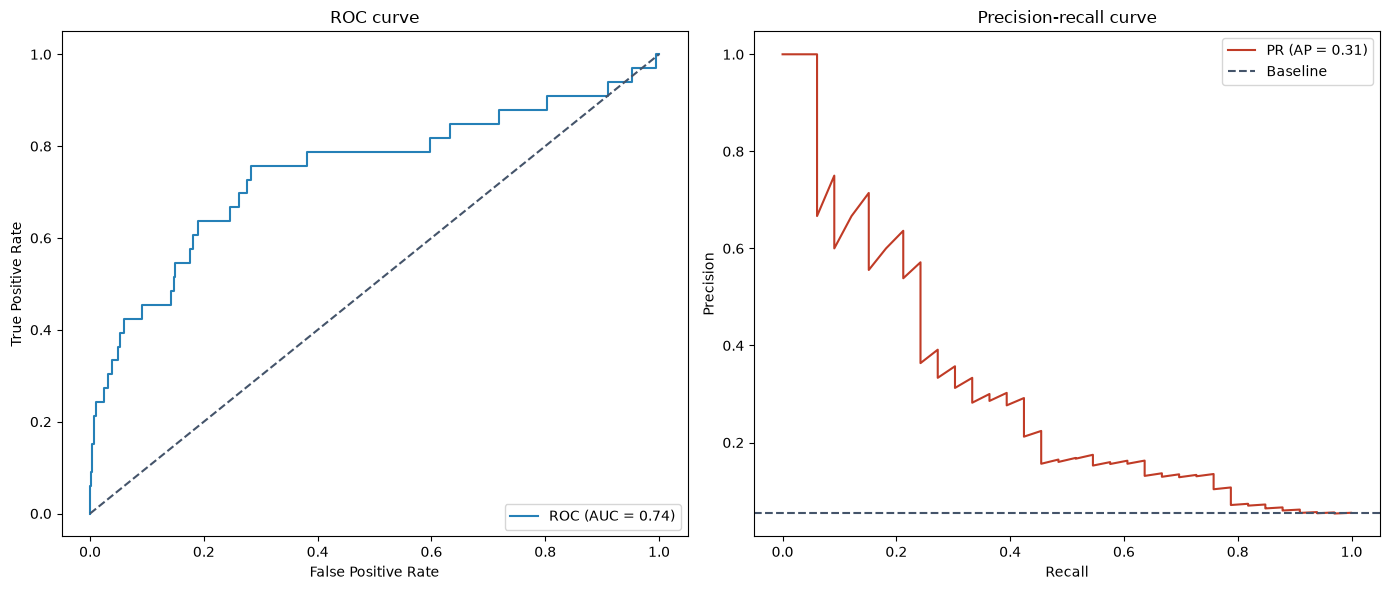

In [4]:
# Plot the ROC and PR curves side by side.
fpr, tpr, _ = roc_curve(y_test, scores)
prec, rec, _ = precision_recall_curve(y_test, scores)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].plot(fpr, tpr, color=colors[1],
             label=f"ROC (AUC = {roc:.2f})")
axes[0].plot([0, 1], [0, 1], color=colors[4], linestyle="--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC curve")
axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, color=colors[3],
             label=f"PR (AP = {ap:.2f})")
axes[1].axhline(y_test.mean(), color=colors[4],
                linestyle="--", label="Baseline")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

## Strategy 1: Balanced Class Weights

Setting `class_weight="balanced"` makes the loss penalise minority errors more heavily.

In [5]:
# Fit a model with balanced class weights.
weighted = LogisticRegression(
    max_iter=5000, class_weight="balanced"
).fit(X_train, y_train)
w_scores = weighted.predict_proba(X_test)[:, 1]
w_ap = average_precision_score(y_test, w_scores)
print(f"Balanced AP: {w_ap:.4f} (baseline {ap:.4f}).")

Balanced AP: 0.1672 (baseline 0.3097).


## Strategy 2: Resampling with NumPy

Random oversampling of the minority class and random undersampling of the majority class, both implemented with NumPy indexing.

In [6]:
# Random oversampling of the minority class with NumPy.
pos_idx = np.where(y_train == 1)[0]
neg_idx = np.where(y_train == 0)[0]
over_idx = np.random.choice(pos_idx, size=len(neg_idx),
                            replace=True)
bal_idx = np.concatenate([neg_idx, over_idx])
X_over, y_over = X_train[bal_idx], y_train[bal_idx]

# Random undersampling of the majority class with NumPy.
under_idx = np.random.choice(neg_idx, size=len(pos_idx),
                             replace=False)
und_idx = np.concatenate([pos_idx, under_idx])
X_under, y_under = X_train[und_idx], y_train[und_idx]

print(f"Oversampled counts:  {np.bincount(y_over)}.")
print(f"Undersampled counts: {np.bincount(y_under)}.")

over_model = LogisticRegression(max_iter=5000)
over_model.fit(X_over, y_over)
o_ap = average_precision_score(
    y_test, over_model.predict_proba(X_test)[:, 1]
)
print(f"Oversampled AP: {o_ap:.4f}.")

Oversampled counts:  [1324 1324].
Undersampled counts: [76 76].
Oversampled AP: 0.1657.


## Strategy 3: Threshold Moving to Maximise F1

Scan the precision-recall thresholds and pick the one that maximises the F1 score on the baseline model.

In [7]:
# Find the threshold that maximises F1.
prec, rec, thr = precision_recall_curve(y_test, scores)
f1_vals = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best = np.argmax(f1_vals)
best_thr = thr[best]
default_f1 = f1_score(y_test, (scores >= 0.5).astype(int))
tuned_f1 = f1_score(y_test, (scores >= best_thr).astype(int))
print(f"Best threshold: {best_thr:.3f}.")
print(f"F1 at 0.5:  {default_f1:.4f}.")
print(f"F1 tuned:   {tuned_f1:.4f}.")

Best threshold: 0.117.
F1 at 0.5:  0.0000.
F1 tuned:   0.3457.


## Compare the Strategies

Summarise the average precision of the baseline against the weighting and resampling strategies.

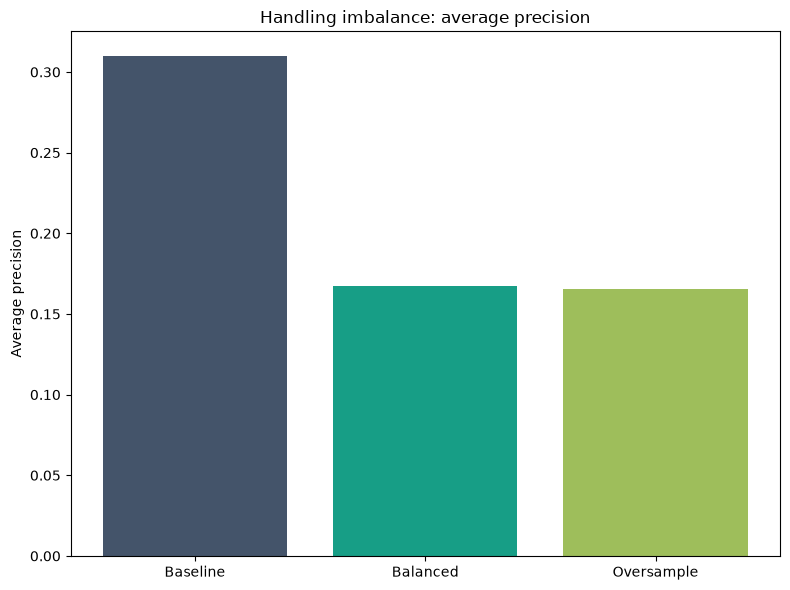

In [8]:
# Compare average precision across the strategies.
u_ap = average_precision_score(
    y_test, over_model.predict_proba(X_test)[:, 1]
)
labels = ["Baseline", "Balanced", "Oversample"]
values = [ap, w_ap, o_ap]
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(labels, values, color=[colors[4], colors[0], colors[2]])
ax.set_ylabel("Average precision")
ax.set_title("Handling imbalance: average precision")
plt.tight_layout()
plt.show()

## Summary

- **PR curve**: focuses on the positive class and, with average precision, is more informative than ROC under imbalance.
- **ROC optimism**: a high ROC AUC can hide poor precision when negatives vastly outnumber positives.
- **class_weight / resampling**: rebalance the training signal so the model attends to the rare class.
- **Threshold moving**: tuning the decision threshold can lift F1 well above the default 0.5 cut.